
# CSE5280 —  Ray Tracing 

**Florida Institute of Technology**



In [15]:
__author__ = 'eribeiro'
#
import numpy as np               # Numpy library
from PIL import Image as im      # Basic image processing library

### Line (ray) equation

The ray equation is given by:

$$
\begin{align}
    {\bf p}\left(t\right) = {\bf e} + {\bf d} t,
\end{align}
$$
where:
$$
\begin{align}
    {\bf d}  = {\bf s} - {\bf e}.
\end{align}
$$


![](https://github.com/eraldoribeiro/raycasting/blob/main/ray.jpg?raw=1)

The diagram shows the main components of the 3-D scene (and virtual camera), i.e.:

- ${\bf e} \in \mathbb{R}^3$ is the eye location (i.e., viewer)

- ${\bf s} \in \mathbb{R}^3$ is a point on the image plane

- ${\bf d} \in \mathbb{R}^3$ is the ray direction

- $f \in \mathbb{R}$ is the focal distance (i.e., perpendicular distance between the center of projection and the image plane.




In [7]:
class Ray:
    """A class representing a ray (line in space).

    Uses the parametric representation of a line, p(t) = e + (s - e)*t.

    The ray passes through the following two points:

    e = [e_u, e_v, e_w] representing the eye location in 3-D, and
    s = [e_u, e_v, e_w] representing a point on the image plane.

    Attributes:
        e: 3x1 np.array, e.g.,
        s: 3x1 np.array
    """

    def __init__(self, e, s):
        """Constructor method

        Args:
            e (3x1 np.array): Eye location
            s (3x1 np.array): Point on the image plane
        """
        self.e = e
        self.s = s


    def get3DPoint(self, t):
        """Calculates the location of a 3-D point along the ray given t.

        Args:
            t (float): Parameter of the ray equation
        Returns:
            p (3x1 nd.array): Point p(t) = e + (s - e) * t.
        """
        p = self.e + (self.s - self.e) * t    # p(t) = e + (s - e) * t

        return p


    


### Sphere equation

The sphere equation in vector form is given by:

$$
\begin{align}
    \left({\bf p} - {\bf c}\right)\cdot \left({\bf p} - {\bf c}\right) - r^2 = 0,
\end{align}
$$

where ${\bf c} \in \mathbb{R}^3$ is the center of the sphere.

#### Ray-sphere intersection
First, we substitute the ray equation into the sphere equation, i.e.:

$$
\begin{align}
    \left({\bf e} + {\bf d}\,t - {\bf c}\right)\cdot \left({\bf e} + {\bf d}\,t - {\bf c}\right) - r^2 = 0.
\end{align}
$$

Then, we expand the dot product (similarly to using the distributive property in multiplication) and re-arrange the terms to obtain:

$$
\begin{align}
    {\left({\bf d}\cdot {\bf d}\right)}t^2 + {2\,{\bf d}\cdot\left({\bf e} - {\bf c}\right)}\,t + {\left({\bf e} - {\bf c}\right) \cdot \left({\bf e} - {\bf c}\right) - r^2} = 0,
\end{align}
$$

which is the classic quadratic equation:

$$
\begin{align}
    {A}t^2 + {B}\,t + {C} = 0.
\end{align}
$$

Its solution for t is given by:

$$
\begin{align}
    t = \frac{-B\pm\sqrt{B^2-4AC}}{2A}.
\end{align}
$$







In [8]:
class Sphere:
    def __init__(self, c, r, k, reflectivity=0.0, transmission=0.0, ior=1.5, roughness=0.0):
        self.Center = c
        self.Radius = r
        self.Color = k
        self.reflectivity = reflectivity
        self.transmission = transmission 
        self.ior = ior
        self.roughness = roughness # 0.0 = mirror, > 0.0 = glossy

    def Intersect(self, ray):
        d = ray.s - ray.e
        e = ray.e
        c = self.Center
        r = self.Radius
        A = np.dot(d, d)
        B = 2.0 * np.dot(d, (e - c))
        C = np.dot((e - c), (e - c)) - r * r
        delta = B*B - 4.0 * A * C
        if delta < 0:
            return float("inf")
        t1 = (-B - np.sqrt(delta)) / (2.0 * A)
        t2 = (-B + np.sqrt(delta)) / (2.0 * A)
        t = np.min([t1, t2])
        return t if t > 0 else float("inf")

    def get_normal(self, p):
        return (p - self.Center) / np.linalg.norm(p - self.Center)

### Converting between image-plane coordinates and image-matrix indices

When creating the rays we need to take into account that the coordinates (i.e., indices) of the image matrix are $(i,j)$ and the coordinates of the image plane are $(u,v)$.  

We also need to remember that the origin of the $(u,v)$-system is at the center of the plane while the origin of the image matrix is (usually) at the top-left corner.

As a result, we must convert between geometric $(u,v)$ coordinates and matrix indices $(i,j)$.

![](https://github.com/eraldoribeiro/raycasting/blob/main/uv_ij.jpg?raw=1)



##  Multiple Viewpoints & Camera Basis

[cite_start]To render from different angles, the camera uses an orthonormal basis $({\bf u, v, w})$ derived from the eye position ${\bf e}$, a "lookat" point, and an "up" vector[cite: 3].

  * **${\bf w}$ (Backward):** $\frac{{\bf e} - \text{lookat}}{\|{\bf e} - \text{lookat}\|}$
  * **${\bf u}$ (Right):** $\frac{\text{up} \times {\bf w}}{\|\text{up} \times {\bf w}\|}$
  * **${\bf v}$ (Up):** ${\bf w} \times {\bf u}$

[cite_start]The switching between viewpoints is implemented by updating these vectors and re-casting the primary rays from the new eye location ${\bf e}$[cite: 3].

In [9]:
class Camera:
    nchannels = 3 

    def __init__(self, f, nrows, ncols, eye, lookat, up):
        self.f = f
        self.nrows = nrows
        self.ncols = ncols
        self.eye = eye
        self.I = np.zeros([self.nrows, self.ncols, self.nchannels])
        

        self.w = (eye - lookat) / np.linalg.norm(eye - lookat)
        
        cross_up_w = np.cross(up, self.w)
        #found weird bug when looking straight down, this fixes it
        if np.linalg.norm(cross_up_w) < 1e-7:
            cross_up_w = np.cross(np.array([1, 0, 0]), self.w)
            
        self.u = cross_up_w / np.linalg.norm(cross_up_w)
        self.v = np.cross(self.w, self.u) # v is up relative to camera

    def ij2uv(self, i, j):
        u_val = (j + 0.5) - self.ncols/2
        v_val = -(i + 0.5) + self.nrows/2
        return u_val, v_val

    def constructRayThroughPixel(self, i, j):
        u_val, v_val = self.ij2uv(i, j)
        direction = u_val * self.u + v_val * self.v - self.f * self.w
        return Ray(self.eye, self.eye + direction)

In [10]:
class HitInformation:
    """A class representing the all the information of objects intersected by a given ray.

    Attributes:
        Object (python class of object): e.g., sphere, cylinder, cone, plane

        p (3x1 np.ndarray): 3-D coordinates of the intersection point
    """
    def __init__(self, intersected_object, intersecton_point):
        self.Object = intersected_object
        self.p = intersecton_point



### The plane equation
The plane through ${\bf p}_1 = \left(u,v,w\right)^\mathsf{T}$, with surface normal ${\bf n} = \left(n_u,n_v,n_w\right)^\mathsf{T}$ is given by the following implicit equation:

$$
\begin{align}
    \left({\bf p} - {\bf p}_1\right) \cdot {\bf n} = 0.
\end{align}
$$

#### Ray-plane intersection

The equation of the ray (line) between the eye and a point on the image plane is given by:

$$
\begin{align}
    {\bf p}\left(t\right) = {\bf e} + {\bf d} t,
\end{align}
$$

where:

$$
\begin{align}
    {\bf d}  = {\bf s} - {\bf e}.
\end{align}
$$

The intersection between the ray and a plane is the point ${\bf p}\left(t\right)$ for:

$$
\begin{align}
    t = \frac{({\bf p}_1 - {\bf e}) \cdot {\bf n}}{{\bf d} \cdot {\bf n}}.
\end{align}
$$




### Calculating the (unit) normal vector of a plane

Select three non-colinear points, use these points to create two vectors on the plane, then calculate their cross product. Normalize the result to obtain the (unit) normal vector.

![](https://github.com/eraldoribeiro/raycasting/blob/main/trinormal.jpg?raw=1)

(Unit) normal vector to the plane:

$$
{\bf n} = \frac{({\bf b} - {\bf a}) \,\times ({\bf c} - {\bf a})}
{\|({\bf b} - {\bf a}) \,\times ({\bf c} - {\bf a})\|}
$$

In [11]:
class Plane:
    def __init__(self, p1, n, k, reflectivity=0.0, transmission=0.0, ior=1.0, roughness=0.0):
        self.p1 = p1
        self.n = n / np.linalg.norm(n) 
        self.Color = k
        self.reflectivity = reflectivity
        self.transmission = transmission
        self.ior = ior
        self.roughness = roughness # 0.0 = mirror, > 0.0 = glossy

    def Intersect(self, ray):
        d = ray.s - ray.e
        e = ray.e
        divide = np.dot(d.flatten(), self.n.flatten()).item()
        if abs(divide) < 1e-6: return float("inf")
        t = np.dot((self.p1.flatten() - e.flatten()), self.n.flatten()).item() / divide
        return t if t > 0 else float("inf")

    def get_normal(self, p):
        return self.n



### Ray and Sphere Equations

[cite_start]The core of the simulation relies on the parametric representation of a ray and its intersection with implicit surfaces[cite: 3].

**Ray Equation:**
$${\bf p}(t) = {\bf e} + {\bf d}t \tag{Eq. 1.1}$$
[cite_start]where ${\bf e}$ is the eye location and ${\bf d} = {\bf s} - {\bf e}$ is the ray direction through a point ${\bf s}$ on the image plane[cite: 3].


###  Shading Model (Lambertian/Diffuse)

[cite_start]The color at an intersection point is determined by the light direction ${\bf l}$ and surface normal ${\bf n}$[cite: 3]:
$$\text{shaded\_color} = (r, g, b) \times \max(0, {\bf l} \cdot {\bf n}) \tag{Eq. 2.1}$$

-----

##  Recursive Ray Tracing

[cite_start]The `trace` function recursively evaluates the scene by finding the closest intersection and calling `shade` to handle secondary rays (reflection/refraction)[cite: 3].

[cite_start]**Algorithm Structure[cite: 3]:**

1.  **Main Loop:** For each pixel $(x, y)$, compute eye ray and call `trace(ray)`.
2.  **Trace Function:** Find the closest intersection $t$ among all surfaces. If hit, return `shade(surface, ray, t)`.
3.  **Shade Function:** Calculate local shading (Phong/Diffuse) and recursively call `trace` for reflected and transmitted directions.

-----

##  Reflection & Refraction

###  Specular Reflection

[cite_start]Ideal mirror reflection is calculated by spawning a new ray in the reflection direction ${\bf r}$[cite: 3]:
$${\bf r} = {\bf d} - 2({\bf d} \cdot {\bf n}){\bf n} \tag{Eq. 4.1}$$
[cite_start]The final color is updated as: $color = color + k_m \times trace(reflected\_ray)$[cite: 3].

###  Refraction (Transmission)

[cite_start]Refraction follows Snell's Law to simulate light passing through dielectrics[cite: 3]:
$$n \sin \theta = n_t \sin \phi \tag{Eq. 4.2}$$
**Transmission Ray Direction:**
$${\bf t} = \frac{n({\bf d} - {\bf n}({\bf d} \cdot {\bf n}))}{n_t} - {\bf n} \sqrt{1 - \frac{n^2(1 - ({\bf d} \cdot {\bf n})^2)}{n_t^2}} \tag{Eq. 4.3}$$

-----

##  Glossy Reflections & Soft Shadows

*Note: This section contains supplementary formulas for distributed ray tracing not found in the basic PowerPoint.*

### Glossy Reflections

Glossy reflection simulates surface roughness by randomly perturbing the ideal reflection vector ${\bf r}$. Instead of one ray, we sample multiple rays within a small area.
$${\bf r}_{perturbed} = \text{normalize}({\bf r} + u{\bf U} + v{\bf V})$$
where $u, v$ are random offsets in a small range $[-a/2, a/2]$, and ${\bf U, V}$ are basis vectors orthogonal to ${\bf r}$.

### Soft Shadows

Soft shadows are achieved by treating light sources as areas (e.g., parallelograms) rather than points. A point on an area light is sampled as:
$${\bf q} = {\bf c} + \xi_1{\bf a} + \xi_2{\bf b}$$
where ${\bf c}$ is a corner, ${\bf a, b}$ are edge vectors, and $\xi_1, \xi_2 \in [0, 1)$. The shadow intensity is the fraction of samples that are not occluded.

-----



In [12]:
class Scene:
    light_source_1 = np.array([0.5, 0.5, 1.0])
    light_source_1 = light_source_1 / np.linalg.norm(light_source_1)

    def __init__(self, theCamera):
        self.theCamera = theCamera
        obj_list = [] 

        # 1. RED ORB: Red and GLOSSY (roughness > 0)
        obj_list.append(Sphere(np.array([-100, 0, -600.0]), 80.0, np.array([255, 0, 0]), 
                               reflectivity=0.5, transmission=0.0, roughness=0.1))

        # 2. GREEN ORB: Green and STATIC
        obj_list.append(Sphere(np.array([120, 0, -500.0]), 80.0, np.array([0, 255, 0]), 
                               reflectivity=0.0, transmission=0.0, roughness=0.0))

        # 3. GLASS MARBLE: In front of Red, offset (High transmission)
        obj_list.append(Sphere(np.array([-140, -20, -400.0]), 60.0, np.array([255, 255, 255]), 
                               reflectivity=0.4, transmission=0.7, ior=1,roughness=0.0))

        

        # 4. FLOOR PLANE: Glossy floor
        obj_list.append(Plane(np.array([0, -100, 0]), np.array([0, 1, 0]), np.array([200, 200, 200]), 
                              reflectivity=0.3, roughness=0.05))

        self.scene_objects = obj_list

    def find_intersection(self, ray):
        hit_list = []
        for surface in self.scene_objects:
            t = surface.Intersect(ray)
            if t != float('inf') and t > 0:
                hit_list.append(HitInformation(surface, ray.get3DPoint(t)))
        return hit_list

    def get_color(self, ray, hit_list):
        return self.cast_ray(ray, depth=0)

    def cast_ray(self, ray, depth=0):
        if depth > 3: return np.array([0, 0, 0])

        hit_list = self.find_intersection(ray)
        if not hit_list: return np.array([0, 0, 0])

        # 1. Find the closest hit (same as before)
        best_hit, best_t = None, float('inf')
        for hit in hit_list:
            t_val = np.linalg.norm(hit.p - ray.e) / np.linalg.norm(ray.s - ray.e)
            if 0 < t_val < best_t:
                best_t, best_hit = t_val, hit
        
        if best_hit is None: return np.array([0, 0, 0])
        hit = best_hit
        obj = hit.Object
        n = obj.get_normal(hit.p)
        l = self.light_source_1
        v = (self.theCamera.eye - hit.p) / np.linalg.norm(self.theCamera.eye - hit.p)
        h = (l + v) / np.linalg.norm(l + v)
        d_norm = (ray.s - ray.e) / np.linalg.norm(ray.s - ray.e)

        shadow_ray = Ray(hit.p + 1e-3 * n, hit.p + l)
        shadow_hits = self.find_intersection(shadow_ray)
        
        # If the shadow ray hits anything, the point is in shadow.
        in_shadow = len(shadow_hits) > 0

        # 2. Phong Shading (Modified for Shadows)
        ambient = 0.1 * obj.Color
        if in_shadow:
            # Only ambient light reaches shaded areas
            diffuse = np.array([0.0, 0.0, 0.0])
            specular = np.array([0.0, 0.0, 0.0])
        else:
            diffuse = 0.6 * max(0.0, np.dot(l, n)) * obj.Color
            specular = 0.5 * (max(0.0, np.dot(h, n))**64) * np.array([255, 255, 255])
        
        local_color = (ambient + diffuse + specular) * (1.0 - obj.transmission)

        # 3. Reflection (Same as Step 4)
        reflect_color = np.array([0.0, 0.0, 0.0])
        if obj.reflectivity > 0:
            ideal_dir = d_norm - 2.0 * np.dot(d_norm, n) * n
            num_samples = 4 if obj.roughness > 0 else 1 
            sample_sum = np.array([0.0, 0.0, 0.0])
            for _ in range(num_samples):
                perturb = (np.random.rand(3) - 0.5) * obj.roughness if obj.roughness > 0 else 0
                sample_dir = ideal_dir + perturb
                sample_dir /= np.linalg.norm(sample_dir)
                sample_sum += self.cast_ray(Ray(hit.p + 1e-3 * n, hit.p + sample_dir), depth + 1)
            reflect_color = sample_sum / num_samples

        # 4. Refraction (Same as Step 3)
        refract_color = np.array([0.0, 0.0, 0.0])
        if obj.transmission > 0:
            cosi = np.clip(np.dot(d_norm, n), -1, 1)
            etai, etat = 1.0, obj.ior
            normal = n
            if cosi > 0: 
                etai, etat = etat, etai
                normal = -n
            else: cosi = -cosi
            eta = etai / etat
            k = 1 - eta**2 * (1 - cosi**2)
            if k >= 0:
                refr_dir = eta * d_norm + (eta * cosi - np.sqrt(k)) * normal
                refract_color = self.cast_ray(Ray(hit.p - 1e-3 * normal, hit.p + refr_dir), depth + 1)
            else:
                refract_color = reflect_color

        # 5. Final Blend
        final_color = local_color + (obj.reflectivity * reflect_color) + (obj.transmission * refract_color)
        return np.clip(final_color, 0, 255)

### Basic ray-tracing/ray-casting algorithm

The basic algorithm for ray tracing is given by:

![](https://github.com/eraldoribeiro/raycasting/blob/main/algorithm.jpg?raw=1)

Rendering front_view...
Saved as scene_front_view.png


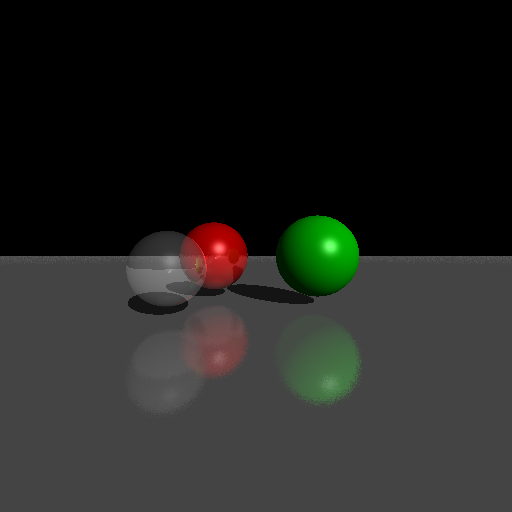

Rendering side_view...
Saved as scene_side_view.png


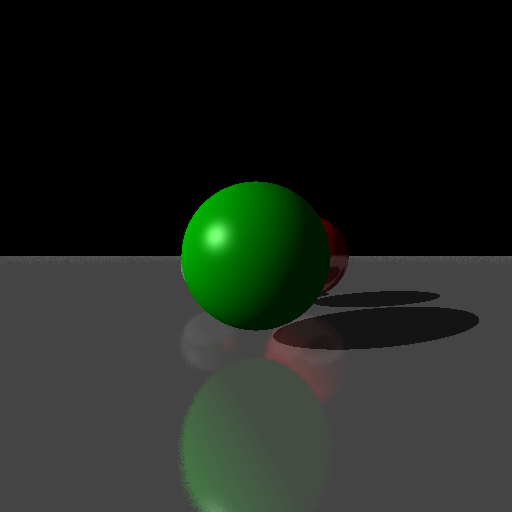

Rendering top_view...
Saved as scene_top_view.png


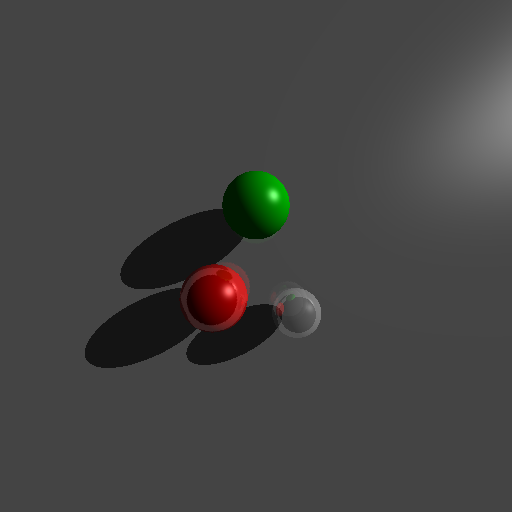

In [13]:
# --- Common Parameters ---
nrows, ncols = 512, 512
f = 250.0
lookat = np.array([0, 0, -500.0]) # Look at the center of the objects
up = np.array([0, 1, 0])          # World Up vector

# --- Define Different Viewpoints (Eye Positions) ---
viewpoints = {
    "front_view": np.array([0, 0, 0]),
    "side_view":  np.array([400, 0, -500]),
    "top_view":   np.array([0, 600, -500])
}

for view_name, eye_pos in viewpoints.items():
    print(f"Rendering {view_name}...")
    
    # 1. Create camera at this viewpoint
    myCamera = Camera(f, nrows, ncols, eye_pos, lookat, up)

    # 2. Create the scene
    theScene = Scene(myCamera)

    # 3. Render
    for i in range(nrows):
        for j in range(ncols):
            ray = myCamera.constructRayThroughPixel(i, j)
            hit = theScene.find_intersection(ray)
            myCamera.I[i,j,:] = theScene.get_color(ray, hit)

    # 4. Save and Show
    out_image = im.fromarray(np.uint8(myCamera.I))
    out_image.save(f'scene_{view_name}.png')
    print(f"Saved as scene_{view_name}.png")
    display(out_image)

whats the max for?

In [14]:
max(3.2,2.1)

3.2